# DTMF example
Werner Schoegler, 15-Oct-2026

In [1]:
# User inputs for DTMF tone generation
# fs: sampling rate in Hz, 
# duration: tone length in s, 
# key: DTMF key 0–9, *, #, A–D”

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq
from scipy.signal.windows import hann

In [3]:
# user inputs
fs, duration, key = 8000, 1.0, '#'

In [4]:
ROW = (697, 770, 852, 941)
COL = (1209, 1336, 1477, 1633)
KEYS = ("123A", "456B", "789C", "*0#D")
DTMF = {}
for r, row in enumerate(KEYS):        # outer loop: rows
    for c, k in enumerate(row):       # inner loop: characters in the row
        DTMF[k] = (ROW[r], COL[c])

# equivalent one-liner using dictionary comprehension
# DTMF = {k: (ROW[r], COL[c]) for r, row in enumerate(KEYS) for c, k in enumerate(row)}

def dtmf_tone(key, amp=1.0, fs=8000, duration=0.1):
    """Return (y, t, f_row, f_col) for a DTMF key; each tone has amplitude amp."""
    try:
        f_row, f_col = DTMF[key.upper()]
    except KeyError:
        raise ValueError(f"Invalid DTMF key: {key!r}") from None
    t = np.arange(int(fs * duration)) / fs
    y = amp * (np.sin(2*np.pi*f_row*t) + np.sin(2*np.pi*f_col*t))
    return y, t, f_row, f_col

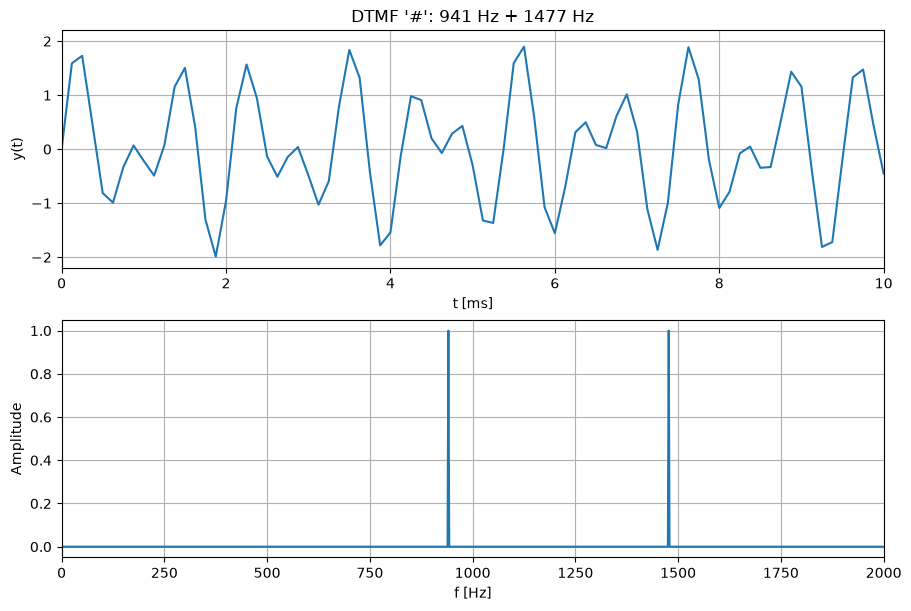

In [5]:
y, time, f_row, f_col = dtmf_tone(key, fs=fs, duration=duration)

N = len(y)

w = hann(N)
Y = rfft(y * w)

freqs = rfftfreq(N, d=1/fs)
amps = 2.0 / w.sum() * np.abs(Y)     # window-corrected amplitude

title = f"DTMF '{key}': {f_row} Hz + {f_col} Hz"
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), constrained_layout=True)

ax1.plot(time * 1e3, y)
ax1.set(xlim=(0, 10), xlabel='t [ms]', ylabel='y(t)', title=title)
ax1.grid(True)

ax2.plot(freqs, amps)
ax2.set(xlim=(0, 2000), xlabel='f [Hz]', ylabel='Amplitude')
ax2.grid(True)
plt.show()